# v2 crop independent CNN: Colab pipeline

Follows `V2_WORKFLOW.md` (Phases 1 to 8) and `crop_indi_cnn/HANDOFF_v2.md`, **crop track only**.

- Task: independent **crop** classifier, 55 classes, 3 backbones (ResNet-50, EfficientNet-B0, ConvNeXt-Tiny), dataset `DPD_Small_clean_v2`.
- The main run uses the dataset's `train_independent.py` **unchanged**. No data preparation, no own improvements here (those go in a separate folder afterwards).
- Every phase ends with a ✅ "you should see" check. If you don't see it, stop (see the troubleshooting table at the end) and ask in the WhatsApp group. Don't work around it silently.

| Phase | What | Where in this notebook |
|---|---|---|
| 1 | Kickoff: read docs, post STARTING | sections 1 |
| 2 | Environment sanity check | section 2 |
| 3 | Smoke test (about 2 min) | section 3 |
| 4 | Main run (about 1.5 h on a T4) | section 4 |
| 5 | Collect and check outputs | section 5 |
| 6 | Run README inputs (SHA-256, analysis) | section 6 |
| 7 | Commit and push | section 7 |
| 8 | DONE message and checkpoints | section 8 |

**Colab notes:** Runtime > Change runtime type > **T4 GPU**. Keep the tab open during the main run. Results are written straight to Google Drive, so finished backbones survive a disconnect.

## Phase 1: kickoff

Do these outside the notebook first:
1. `git pull` the repo at the commit from the `[v2 dataset] READY` message.
2. Read `V2_WORKFLOW.md`, then `crop_indi_cnn/README.md` and `HANDOFF_v2.md`.
3. Read the dataset's `README.md` ("Quick start", "Shared protocol") and `V2_CHANGES.md` (the cells below print them).
4. **Sync point:** post the STARTING message in the group (the cell below fills it in).

✅ All three owners replied with the **same Kaggle version and commit**. If anyone's differs, fix it now, not after training.

**Rules that keep the tracks comparable:** dataset loader and augmentation unchanged; never use `test_seen` / `test_unseen` to choose epochs, learning rates or models; best epoch = highest harmonic mean of `val` and `val_unseen` Top-1 (patience 10); seed 42, batch 64, up to 30 epochs, AdamW wd 0.05; pinned ImageNet-1k weights; main run first and unchanged; never edit or delete the v1 results folder `output/crop_independent/`.

In [18]:
from google.colab import drive
import os, glob, zipfile, shutil
drive.mount("/content/drive")

# ----------------------------- EDIT THESE -----------------------------
ZIP_PATH       = "/content/drive/MyDrive/archive.zip"   # dataset zip in your Drive
KAGGLE_VERSION = "2"
REPO_COMMIT    = "abc1234"
# ----------------------------------------------------------------------

assert os.path.isfile(ZIP_PATH), f"Zip not found: {ZIP_PATH}"
assert "<" not in KAGGLE_VERSION and "<" not in REPO_COMMIT, "Fill in KAGGLE_VERSION and REPO_COMMIT."

DATA = "/content/DPD_Small_clean_v2"                               # local copy
OUT  = "/content/drive/MyDrive/DPD_runs/v2/crop_independent_v2"    # results go to Drive

# always start clean (a previous failed run may have left the wrong folder behind)
shutil.rmtree(DATA, ignore_errors=True)
shutil.rmtree("/content/_extract", ignore_errors=True)

# copy the zip to local disk first (one big file is fast), then extract locally
shutil.copy(ZIP_PATH, "/content/archive.zip")
with zipfile.ZipFile("/content/archive.zip") as z:
    z.extractall("/content/_extract")

# pick the folder that contains train_independent.py
hits = [os.path.dirname(p) for p in glob.glob("/content/_extract/**/train_independent.py", recursive=True)]
if not hits:
    print("train_independent.py NOT found in the zip. label_maps.json copies found at:")
    for p in glob.glob("/content/_extract/**/label_maps.json", recursive=True):
        print("  ", p, "->", sorted(os.listdir(os.path.dirname(p)))[:12])
    raise AssertionError("No train_independent.py in the zip: this is not the v2 dataset.")
assert os.path.exists(f"{hits[0]}/label_maps.json"), f"train_independent.py found in {hits[0]} but label_maps.json is not next to it."
shutil.move(hits[0], DATA)

print("DATA:", DATA)
print("OUT :", OUT)
print(sorted(os.listdir(DATA))[:20])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DATA: /content/DPD_Small_clean_v2
OUT : /content/drive/MyDrive/DPD_runs/v2/crop_independent_v2
['README.md', 'V2_CHANGES.md', '__init__.py', 'dataset.py', 'images', 'label_maps.json', 'manifest.csv', 'metrics.py', 'stats.json', 'test_seen.csv', 'test_unseen.csv', 'train.csv', 'train_independent.py', 'val.csv', 'val_unseen.csv']


In [19]:
!cp -r "{DRIVE_DATASET}" /content/

assert os.path.exists(f"{DATA}/label_maps.json"), "label_maps.json missing: wrong folder or incomplete copy."
assert os.path.exists(f"{DATA}/train_independent.py"), "train_independent.py missing from the dataset folder."
print(sorted(os.listdir(DATA)))

cp: cannot stat '/content/drive/MyDrive/archive': No such file or directory
['README.md', 'V2_CHANGES.md', '__init__.py', 'dataset.py', 'images', 'label_maps.json', 'manifest.csv', 'metrics.py', 'stats.json', 'test_seen.csv', 'test_unseen.csv', 'train.csv', 'train_independent.py', 'val.csv', 'val_unseen.csv']


In [21]:
# Post this in the WhatsApp group (sync point)
print(f"[v2 crop_independent] STARTING – Kaggle v{KAGGLE_VERSION}, commit {REPO_COMMIT}")

[v2 crop_independent] STARTING – Kaggle v2, commit abc1234


In [22]:
# Read: dataset README "Quick start" and "Shared protocol"
def show_section(path, keywords, max_lines=80):
    if not os.path.exists(path):
        print(f"[missing] {path}"); return
    lines = open(path, encoding="utf-8").read().splitlines()
    for kw in keywords:
        start = next((i for i, l in enumerate(lines) if l.lstrip().startswith("#") and kw.lower() in l.lower()), None)
        if start is None:
            print(f"[no section matching '{kw}' in {os.path.basename(path)}]"); continue
        level = len(lines[start]) - len(lines[start].lstrip("#"))
        end = len(lines)
        for j in range(start + 1, len(lines)):
            if lines[j].startswith("#") and (len(lines[j]) - len(lines[j].lstrip("#"))) <= level:
                end = j; break
        print("=" * 80)
        print("\n".join(lines[start:min(end, start + max_lines)]))
        print()

show_section(f"{DATA}/README.md", ["Quick start", "Shared protocol"])

## Quick start

The loader finds its CSVs and images relative to its own file, so it works wherever the folder is (Kaggle, Colab, local). Import it as a plain module:

```python
import glob, os, sys


## Shared protocol (all three model tracks)

Same rules for everyone, so the results can go in one table.

1. **Train on `train` only.** `test_seen` and `test_unseen` are used **once**, after training, for the final numbers. Never for early stopping, learning-rate choice or backbone choice.
2. **Use `get_loaders()` as is** (same augmentation, no sampler, no class weights).
3. **Settings:** image 224, batch 64, seed 42, up to 30 epochs, early-stopping patience 10, AdamW (weight decay 0.05), label smoothing 0.1. Learning rate per backbone: ResNet-50 3e-4, EfficientNet-B0 5e-4, ConvNeXt-Tiny 1e-4 (multitask may use its own, write it down).
   **Pretrained weights (pinned, ImageNet-1k):** timm `resnet50.tv2_in1k`, `efficientnet_b0.ra_in1k`, `convnext_tiny.fb_in1k`. These equal torchvision's d

In [23]:
# Read: V2_CHANGES.md (section 7 describes what each data-preparation script did; useful for the report)
!cat {DATA}/V2_CHANGES.md

# DPD_Small_clean_v2: what changed, and why

**Short version:** same images and same official test sets as v1. v2 adds a validation set of **held-out crop+disease pairs** (`val_unseen.csv`), five metadata columns, a shared evaluation protocol, and a loader that supports all of it. The goal is to let every model be tuned and compared on what the brief actually measures: the harmonic mean of seen and unseen accuracy.

---

## 1. Original vs v1 vs v2

| | Original DPD-Small | v1 `DPD_Small_clean` | v2 `DPD_Small_clean_v2` |
|---|---|---|---|
| Images | 11,448, mixed sizes and formats (PNG/WEBP named .jpg, RGBA, EXIF-rotated) | 11,443, 224×224 RGB JPEG, EXIF applied | **same as v1** (rebuilt from raw with the v1 code; identical processing) |
| Near-duplicates of test images in train | 5 | removed | removed |
| Train | 8,000 (official) | 7,200 | **6,995** |
| Validation (seen pairs) | none | `val.csv` 795 (10% per pair, near-duplicate-aware) | `val.csv` **773** (v1 val minus held-out pairs)

## Phase 2: environment sanity check

Colab replaces the Kaggle "Add Input / Settings" steps: pick the T4 runtime (internet is on by default, needed for the pretrained weights).

✅ You should see a GPU name (e.g. `Tesla T4`), `cuda True`, and exactly:
```
{'train': 6995, 'val': 773, 'val_unseen': 227, 'test_seen': 2000, 'test_unseen': 1448}
```

In [24]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
!pip -q install timm

name, memory.total [MiB]
Tesla T4, 15360 MiB


In [25]:
import sys
sys.path.insert(0, DATA)
import torch, timm, dataset

print("DATA:", DATA)
print("torch", torch.__version__, "| timm", timm.__version__, "| cuda", torch.cuda.is_available())
sizes = {s: len(dataset.read_split(s)) for s in dataset.SPLITS}
print(sizes)

EXPECTED = {"train": 6995, "val": 773, "val_unseen": 227, "test_seen": 2000, "test_unseen": 1448}
assert torch.cuda.is_available(), "cuda False: Runtime > Change runtime type > T4 GPU"
assert sizes == EXPECTED, "Split sizes differ: wrong dataset version (v1 attached?). Stop and post in the group."
print("OK: GPU available and split sizes match v2.")

DATA: /content/DPD_Small_clean_v2
torch 2.11.0+cu130 | timm 1.0.30 | cuda True
{'train': 6995, 'val': 773, 'val_unseen': 227, 'test_seen': 2000, 'test_unseen': 1448}
OK: GPU available and split sizes match v2.


## Phase 3: smoke test (about 2 minutes)

One epoch, 3 batches, ResNet-50 only. The accuracy numbers are meaningless; only check that the pipeline runs.

✅ You should see a line `split sizes: {'train': 6995, ...} | device: cuda`, one epoch line like `[ResNet50] ep 01 | train loss … | val … | val_unseen … | H …`, then a one-row summary table, and `/content/smoke/` containing `results.json`, `summary.csv`, confusion matrices and prediction files.

In [26]:
!python {DATA}/train_independent.py --task crop --out /content/smoke --models ResNet50 --epochs 1 --limit-batches 3 --workers 2

split sizes: {'train': 6995, 'val': 773, 'val_unseen': 227, 'test_seen': 2000, 'test_unseen': 1448} | device: cuda

===== ResNet50 (resnet50.tv2_in1k) =====

model.safetensors: downloading bytes:   0% 0.00/102M [00:00<?, ?B/s]
model.safetensors: downloading bytes:  91% 93.1M/102M [00:01<00:00, 122MB/s, 6.63MB/s  ] 
model.safetensors: downloading bytes: 100% 96.5M/96.5M [00:01<00:00, 52.0MB/s, 9.12MB/s  ]
model.safetensors: reconstructing file: 100% 102M/102M [00:01<00:00, 55.3MB/s, 9.86MB/s  ]
[ResNet50] ep 01 | train loss 3.9405 acc(aug) 7.29 | val 3.12 | val_unseen 3.12 | H 3.12 | 12s
{
 "best_epoch": 1,
 "seen": {
  "1": 7.8125,
  "3": 17.1875,
  "5": 24.47916716337204,
  "per_class_top1": 1.8212128908206253
 },
 "unseen": {
  "1": 3.125,
  "3": 17.1875,
  "5": 27.08333432674408,
  "per_class_top1": 3.125
 },
 "harmonic": {
  "1": 4.464285714285714,
  "3": 17.1875,
  "5": 25.71548893736061,
  "per_class_top1": 2.3012718657446274
 }
}
   Model  Val Top-1  Val-unseen Top-1  Seen Top-1

In [27]:
smoke = "/content/smoke"
names = sorted(os.listdir(smoke))
print(names)
assert "results.json" in names and "summary.csv" in names, "smoke run did not write results.json / summary.csv"
assert any("confusion_matrix" in n for n in names), "no confusion matrices in smoke output"
assert any("predictions" in n for n in names), "no prediction files in smoke output"
print("Smoke test OK.")

['ResNet50_best.pt', 'ResNet50_curves.png', 'ResNet50_history.csv', 'ResNet50_predictions_seen.csv', 'ResNet50_predictions_unseen.csv', 'ResNet50_predictions_val.csv', 'ResNet50_predictions_val_unseen.csv', 'ResNet50_seen_confusion_matrix.csv', 'ResNet50_seen_confusion_matrix.png', 'ResNet50_unseen_confusion_matrix.csv', 'ResNet50_unseen_confusion_matrix.png', 'ResNet50_val_confusion_matrix.csv', 'ResNet50_val_confusion_matrix.png', 'ResNet50_val_unseen_confusion_matrix.csv', 'ResNet50_val_unseen_confusion_matrix.png', 'all_models_accuracy.png', 'config.json', 'harmonic_mean.png', 'results.json', 'summary.csv']
Smoke test OK.


In [28]:
# Delete the smoke folder, as the workflow says
!rm -rf /content/smoke

## Phase 4: main run (about 1.5 h on a T4)

The command is the handoff's Colab command, script unchanged, `--workers 2`, output on Drive.

What is normal while it runs:
- One line per epoch with `val`, `val_unseen` and `H`. **`val_unseen` is small (227 images) and jumps a few points between epochs.** That is expected; the best epoch is chosen on `H`.
- Early stopping prints `early stop at epoch N` when `H` hasn't improved for 10 epochs. Runs often end before epoch 30.
- `results.json` is rewritten after each backbone, so finished backbones are safe even if a later one crashes.

✅ The run finishes and prints the final summary table with **3 rows**.

Keep this notebook's outputs: it must be saved **with outputs** as `crop_independent_cnns_v2.ipynb`.

In [31]:
OUT_LOCAL = "/content/crop_independent_v2"      # train on local disk (reliable)
!python {DATA}/train_independent.py --task crop --workers 2 --out {OUT_LOCAL}

# copy results to Drive afterwards (later cells read from OUT on Drive)
!mkdir -p "{OUT}" && cp -r {OUT_LOCAL}/. "{OUT}/" && ls "{OUT}" | head -60

split sizes: {'train': 6995, 'val': 773, 'val_unseen': 227, 'test_seen': 2000, 'test_unseen': 1448} | device: cuda

===== ResNet50 (resnet50.tv2_in1k) =====
[ResNet50] ep 01 | train loss 3.3201 acc(aug) 34.62 | val 59.12 | val_unseen 39.21 | H 47.15 | 69s
[ResNet50] ep 02 | train loss 1.5095 acc(aug) 76.51 | val 88.62 | val_unseen 66.96 | H 76.28 | 69s
[ResNet50] ep 03 | train loss 1.0865 acc(aug) 89.42 | val 91.07 | val_unseen 78.41 | H 84.27 | 68s
[ResNet50] ep 04 | train loss 0.9598 acc(aug) 93.19 | val 92.88 | val_unseen 87.67 | H 90.20 | 67s
[ResNet50] ep 05 | train loss 0.8878 acc(aug) 95.33 | val 92.76 | val_unseen 85.02 | H 88.72 | 69s
[ResNet50] ep 06 | train loss 0.8457 acc(aug) 96.79 | val 93.40 | val_unseen 85.46 | H 89.26 | 67s
[ResNet50] ep 07 | train loss 0.8115 acc(aug) 97.66 | val 93.79 | val_unseen 87.22 | H 90.39 | 68s
[ResNet50] ep 08 | train loss 0.7968 acc(aug) 98.25 | val 94.18 | val_unseen 86.34 | H 90.09 | 70s
[ResNet50] ep 09 | train loss 0.7790 acc(aug) 98.82

**If the run stopped half-way** (Colab disconnect, quota): finished backbones are in `results.json`. Reconnect, re-run the cells in sections 1 and 2, then rerun only the missing backbone(s), one `--models` name at a time, into the **same** `--out` folder. Uncomment and adapt the line below, and write it in your README's process log. Post in the group that you had to resume.

In [ ]:
# !python {DATA}/train_independent.py --task crop --workers 2 --out {OUT} --models ConvNeXt-Tiny

## Phase 5: collect and check the outputs

The results are already in Drive at `OUT`. This section checks them against the workflow and the handoff (section 4).

✅ The file count is 47; every model has a best epoch; seen > unseen; nothing is exactly 0 or 100; `train_clean_top1` is below 100%.

In [32]:
import json
import pandas as pd

MODELS = ["ResNet50", "EfficientNet-B0", "ConvNeXt-Tiny"]
SPLITS = ["val", "val_unseen", "seen", "unseen"]

# 1) File count: 47 = 3 x 14 (4 confusion CSVs + 4 PNGs + 4 prediction CSVs + history + curves) + 5 shared files
expected = {"config.json", "results.json", "summary.csv", "all_models_accuracy.png", "harmonic_mean.png"}
for m in MODELS:
    expected |= {f"{m}_history.csv", f"{m}_curves.png"}
    for s in SPLITS:
        expected |= {f"{m}_{s}_confusion_matrix.csv", f"{m}_{s}_confusion_matrix.png", f"{m}_predictions_{s}.csv"}

actual = {f for f in os.listdir(OUT) if not f.endswith(".pt") and f != "README.md"}
print("files (excluding .pt and README.md):", len(actual), "| expected:", len(expected))
print("missing:", sorted(expected - actual) or "none")
print("unexpected extra:", sorted(actual - expected) or "none")
assert len(expected) == 47
assert not (expected - actual), "Missing output files. Stop; see troubleshooting."

# 2) Checkpoints exist
for m in MODELS:
    assert os.path.exists(f"{OUT}/{m}_best.pt"), f"{m}_best.pt missing"

# 3) config.json: dataset, pinned timm_ids, GPU name
cfg = json.load(open(f"{OUT}/config.json"))
print(json.dumps(cfg, indent=2))
assert cfg.get("dataset") == "DPD_Small_clean_v2", "config.json dataset is not DPD_Small_clean_v2"

# 4) summary.csv has 3 rows
summary = pd.read_csv(f"{OUT}/summary.csv")
display(summary)
assert len(summary) == 3, "summary.csv should have 3 rows"

files (excluding .pt and README.md): 47 | expected: 47
missing: none
unexpected extra: none
{
  "task": "crop",
  "out": "/content/crop_independent_v2",
  "models": {
    "ResNet50": {
      "timm_id": "resnet50.tv2_in1k",
      "lr": 0.0003
    },
    "EfficientNet-B0": {
      "timm_id": "efficientnet_b0.ra_in1k",
      "lr": 0.0005
    },
    "ConvNeXt-Tiny": {
      "timm_id": "convnext_tiny.fb_in1k",
      "lr": 0.0001
    }
  },
  "epochs": 30,
  "patience": 10,
  "batch_size": 64,
  "workers": 2,
  "seed": 42,
  "label_smooth": 0.1,
  "weight_decay": 0.05,
  "no_pretrained": false,
  "limit_batches": 0,
  "dataset": "DPD_Small_clean_v2",
  "protocol": "best epoch = max H(val Top-1, val_unseen Top-1)",
  "optimizer": "AdamW",
  "schedule": "OneCycleLR pct_start=0.1",
  "amp": true,
  "device": "cuda",
  "gpu": "Tesla T4",
  "versions": {
    "python": "3.13.16",
    "torch": "2.11.0+cu130",
    "timm": "1.0.30"
  }
}


,Model,Val Top-1,Val-unseen Top-1,Seen Top-1,Unseen Top-1,H Top-1,Seen Top-3,Unseen Top-3,H Top-3,Seen Top-5,Unseen Top-5,H Top-5,Seen excl. held-out Top-1,Seen per-class Top-1,Unseen per-class Top-1,Train (clean) Top-1
0,ResNet50,94.05,93.83,88.05,65.33,75.01,93.55,79.07,85.71,95.45,83.22,88.92,88.20,59.57,61.51,99.37
1,EfficientNet-B0,96.12,88.55,89.35,67.61,76.97,93.40,77.90,84.95,94.75,81.70,87.74,89.43,62.48,63.49,100.00
2,ConvNeXt-Tiny,95.73,88.55,88.90,70.23,78.47,93.75,81.35,87.11,95.35,83.98,89.30,89.02,59.87,64.69,98.40


In [33]:
# 5) Sanity check of the numbers (from V2_WORKFLOW.md) plus clean-train check (HANDOFF section 4)
res = json.load(open(f"{OUT}/results.json"))
problems = []
for m, x in res.items():
    s = x.get("pair", x)
    seen, unseen, H = s["seen"]["1"], s["unseen"]["1"], s["harmonic"]["1"]
    print(f"{m:16s} best epoch {x['best_epoch']:>2} (ran {x['epochs_run']:>2}) | seen {seen:.1f} | unseen {unseen:.1f} | H {H:.1f} "
          f"| train_clean_top1 {x['train_clean_top1']:.1f} | timm_id {x['timm_id']}")
    if not seen > unseen: problems.append(f"{m}: seen <= unseen")
    if any(v in (0, 0.0, 100, 100.0) for v in (seen, unseen, H)): problems.append(f"{m}: a headline number is exactly 0 or 100")
    if not x["train_clean_top1"] < 100: problems.append(f"{m}: train_clean_top1 is 100% (is augmentation on?)")
print("\nProblems:", problems or "none")
if problems:
    print("Stop, don't push: post the summary table in the group.")

ResNet50         best epoch  9 (ran 19) | seen 88.1 | unseen 65.3 | H 75.0 | train_clean_top1 99.4 | timm_id resnet50.tv2_in1k
EfficientNet-B0  best epoch 25 (ran 30) | seen 89.3 | unseen 67.6 | H 77.0 | train_clean_top1 100.0 | timm_id efficientnet_b0.ra_in1k
ConvNeXt-Tiny    best epoch  9 (ran 19) | seen 88.9 | unseen 70.2 | H 78.5 | train_clean_top1 98.4 | timm_id convnext_tiny.fb_in1k

Problems: ['EfficientNet-B0: train_clean_top1 is 100% (is augmentation on?)']
Stop, don't push: post the summary table in the group.


In [34]:
# Results table (Top-1, %), copy into the README. For the v1 comparison use seen_excl_heldout, not seen.
rows = []
for m, r in res.items():
    rows.append({
        "Model": m, "best_epoch": r["best_epoch"], "epochs_run": r["epochs_run"],
        "val": r["val"]["1"], "val_unseen": r["val_unseen"]["1"],
        "seen": r["seen"]["1"], "seen_excl_heldout": r["seen_excl_heldout"]["1"],
        "unseen": r["unseen"]["1"], "H top1": r["harmonic"]["1"], "H top5": r["harmonic"]["5"],
        "seen per-class": r["seen"]["per_class_top1"], "unseen per-class": r["unseen"]["per_class_top1"],
    })
display(pd.DataFrame(rows).round(2))

,Model,best_epoch,epochs_run,val,val_unseen,seen,seen_excl_heldout,unseen,H top1,H top5,seen per-class,unseen per-class
0,ResNet50,9,19,94.05,93.83,88.05,88.20,65.33,75.01,88.92,59.57,61.51
1,EfficientNet-B0,25,30,96.12,88.55,89.35,89.43,67.61,76.97,87.74,62.48,63.49
2,ConvNeXt-Tiny,9,19,95.73,88.55,88.90,89.02,70.23,78.47,89.30,59.87,64.69


ResNet50


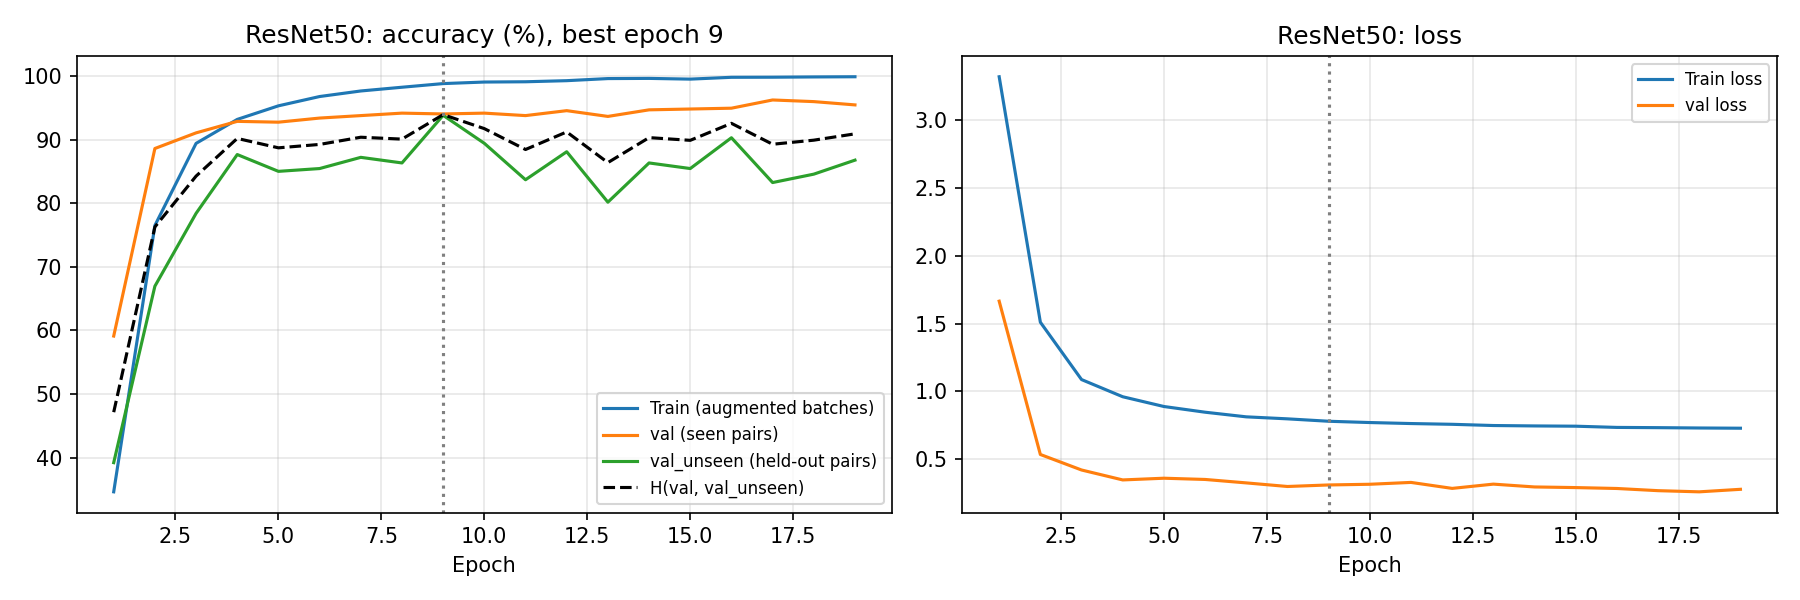

EfficientNet-B0


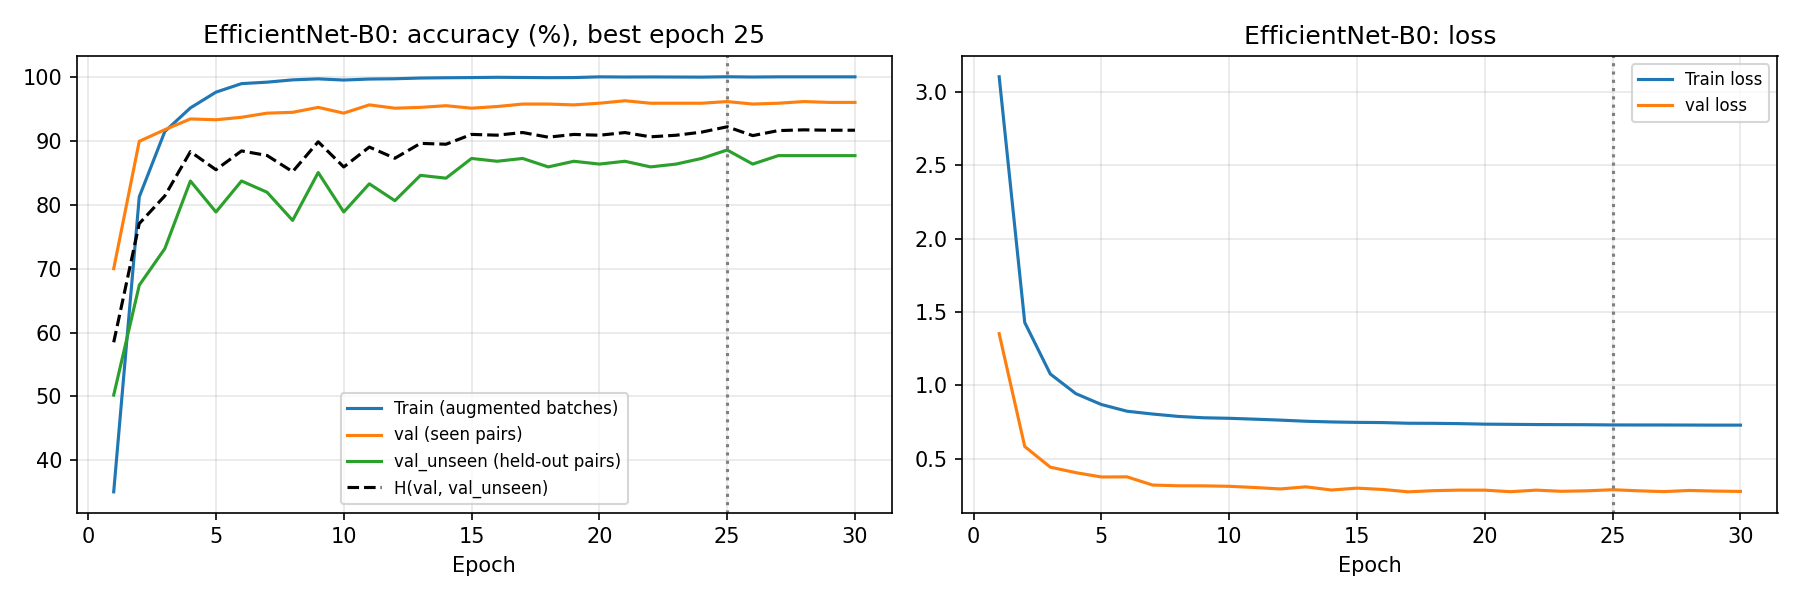

ConvNeXt-Tiny


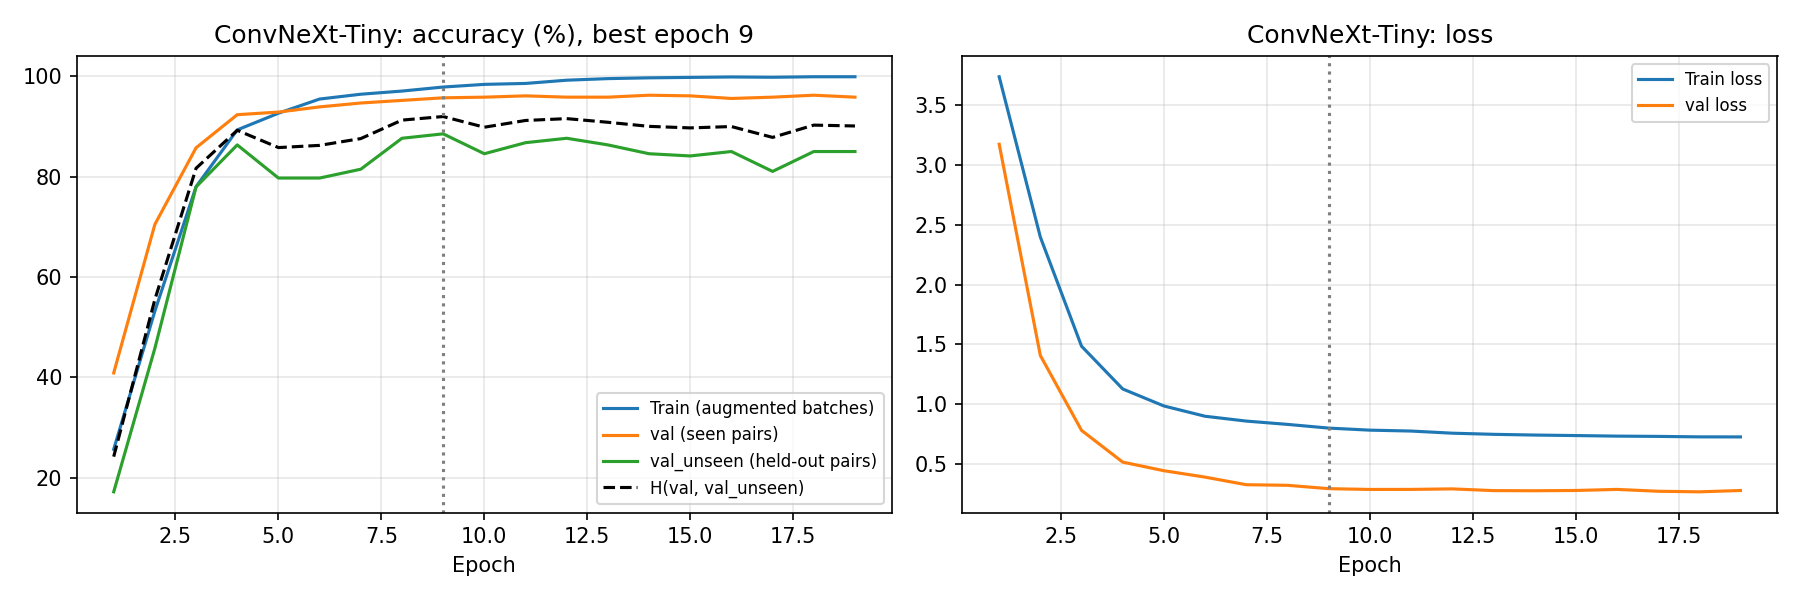

ResNet50 history columns: ['epoch', 'train_loss', 'train_acc_aug', 'val_loss', 'val_acc', 'val_unseen_acc', 'val_H', 'secs']
EfficientNet-B0 history columns: ['epoch', 'train_loss', 'train_acc_aug', 'val_loss', 'val_acc', 'val_unseen_acc', 'val_H', 'secs']
ConvNeXt-Tiny history columns: ['epoch', 'train_loss', 'train_acc_aug', 'val_loss', 'val_acc', 'val_unseen_acc', 'val_H', 'secs']


In [35]:
# Handoff check: train_acc_aug should rise more slowly than in v1 (augmentation on). Look at the curves.
from IPython.display import Image, display as ipy_display
for m in MODELS:
    print(m)
    ipy_display(Image(f"{OUT}/{m}_curves.png", width=800))

for m in MODELS:
    h = pd.read_csv(f"{OUT}/{m}_history.csv")
    print(m, "history columns:", list(h.columns))

## Phase 6: inputs for your run README

Copy `crop_indi_cnn/README_TEMPLATE.md` into the results folder as `README.md` and fill in **every** section: environment, exact commands, pipeline (plus any change from the protocol, normally none), process log (smoke test, crashes, resumes), training behaviour, results (from `summary.csv`, plus the v1 comparison using `seen_excl_heldout`), error analysis, checkpoints.

The cells below print the values you need.

In [36]:
# Environment for the README
import platform, subprocess
print("Python:", platform.python_version(), "| torch", torch.__version__, "| timm", timm.__version__)
print("GPU:", torch.cuda.get_device_name(0))
print("Kaggle dataset version:", KAGGLE_VERSION, "| repo commit:", REPO_COMMIT)
print("Workers: 2 | Command: python train_independent.py --task crop --workers 2 --out", OUT)

Python: 3.13.16 | torch 2.11.0+cu130 | timm 1.0.30
GPU: Tesla T4
Kaggle dataset version: 2 | repo commit: abc1234
Workers: 2 | Command: python train_independent.py --task crop --workers 2 --out /content/drive/MyDrive/DPD_runs/v2/crop_independent_v2


In [37]:
# Training behaviour: best epoch, time per epoch, train vs val gap
for m in MODELS:
    h = pd.read_csv(f"{OUT}/{m}_history.csv")
    sec = [c for c in h.columns if "sec" in c.lower()]
    print(f"\n{m}: {len(h)} epochs | best epoch (results.json) {res[m]['best_epoch']}")
    if sec: print(f"  mean seconds/epoch: {h[sec[0]].mean():.0f}")
    display(h.tail(3).round(3))


ResNet50: 19 epochs | best epoch (results.json) 9
  mean seconds/epoch: 69


,epoch,train_loss,train_acc_aug,val_loss,val_acc,val_unseen_acc,val_H,secs
16,17,0.732,99.828,0.267,96.248,83.260,89.284,68.7
17,18,0.729,99.871,0.258,95.990,84.582,89.925,70.4
18,19,0.728,99.900,0.277,95.472,86.784,90.921,68.5



EfficientNet-B0: 30 epochs | best epoch (results.json) 25
  mean seconds/epoch: 67


,epoch,train_loss,train_acc_aug,val_loss,val_acc,val_unseen_acc,val_H,secs
27,28,0.73,99.986,0.285,96.119,87.665,91.698,68.4
28,29,0.73,99.986,0.281,95.990,87.665,91.639,66.6
29,30,0.73,99.986,0.279,95.990,87.665,91.639,65.8



ConvNeXt-Tiny: 19 epochs | best epoch (results.json) 9
  mean seconds/epoch: 72


,epoch,train_loss,train_acc_aug,val_loss,val_acc,val_unseen_acc,val_H,secs
16,17,0.731,99.828,0.273,95.860,81.057,87.839,71.2
17,18,0.727,99.928,0.268,96.248,85.022,90.288,73.6
18,19,0.727,99.928,0.279,95.860,85.022,90.116,71.8


In [38]:
# Error analysis for the report (HANDOFF section 6): per-class unseen accuracy; tomato is 33% of test_unseen
for m in MODELS:
    print("=" * 70); print(m)
    r = res[m]
    print(f"seen: overall {r['seen']['1']:.1f} vs per-class {r['seen']['per_class_top1']:.1f}   |   "
          f"unseen: overall {r['unseen']['1']:.1f} vs per-class {r['unseen']['per_class_top1']:.1f}")
    p = pd.read_csv(f"{OUT}/{m}_predictions_unseen.csv")
    if not {"true", "pred1"} <= set(p.columns):
        print("columns:", list(p.columns)); continue
    p["correct"] = p["true"] == p["pred1"]
    g = p.groupby("true")["correct"].agg(acc="mean", n="size")
    g["acc"] *= 100
    g["share_%"] = g["n"] / g["n"].sum() * 100
    print("largest share of test_unseen:")
    display(g.sort_values("n", ascending=False).head(3).round(1))
    print("worst 8 classes (n >= 10):")
    display(g[g["n"] >= 10].sort_values("acc").head(8).round(1))
    key = g[g.index.astype(str).str.contains("tomato|cherry|cucumber|pepper", case=False)]
    print("tomato / cherry / cucumber / pepper:")
    display(key.round(1))

ResNet50
seen: overall 88.1 vs per-class 59.6   |   unseen: overall 65.3 vs per-class 61.5
largest share of test_unseen:


,acc,n,share_%
true,,,
tomato,82.8,472,32.6
grape,57.6,271,18.7
pepper_bell,49.1,220,15.2


worst 8 classes (n >= 10):


,acc,n,share_%
true,,,
cherry,0.0,72,5.0
cucumber,37.7,69,4.8
pepper_bell,49.1,220,15.2
grape,57.6,271,18.7
cotton,61.6,125,8.6
mango,78.9,95,6.6
tomato,82.8,472,32.6
sugarcane,88.8,89,6.1


tomato / cherry / cucumber / pepper:


,acc,n,share_%
true,,,
cherry,0.0,72,5.0
cucumber,37.7,69,4.8
pepper_bell,49.1,220,15.2
tomato,82.8,472,32.6


... (8 outputs left out)

worst 8 classes (n >= 10):


,acc,n,share_%
true,,,
cherry,0.0,72,5.0
cucumber,44.9,69,4.8
grape,64.6,271,18.7
cotton,68.0,125,8.6
pepper_bell,74.1,220,15.2
sugarcane,75.3,89,6.1
tomato,81.8,472,32.6
mango,82.1,95,6.6


tomato / cherry / cucumber / pepper:


,acc,n,share_%
true,,,
cherry,0.0,72,5.0
cucumber,44.9,69,4.8
pepper_bell,74.1,220,15.2
tomato,81.8,472,32.6


In [39]:
# Checkpoint list for the README: file, size, SHA-256, epoch, val H. Fill the "date sent" column in Phase 8.
!ls -lh {OUT}/*.pt
!sha256sum {OUT}/*.pt

for m in MODELS:
    ck = torch.load(f"{OUT}/{m}_best.pt", map_location="cpu")
    print(f"{m:16s} epoch {ck['epoch']:>2} | val_H {ck['val_H']:.2f} | val_top1 {ck['val_top1']:.2f} | val_unseen_top1 {ck['val_unseen_top1']:.2f} | {ck['dataset']} | {ck['timm_id']}")
    mdl = timm.create_model(ck["timm_id"], pretrained=False, num_classes=ck["num_classes"])
    mdl.load_state_dict(ck["state_dict"])
print("All 3 checkpoints reload OK.")

-rw------- 1 root root 107M Nov  4 01:32  /content/drive/MyDrive/DPD_runs/v2/crop_independent_v2/ConvNeXt-Tiny_best.pt
-rw------- 1 root root  16M Nov  4 01:32  /content/drive/MyDrive/DPD_runs/v2/crop_independent_v2/EfficientNet-B0_best.pt
-rw------- 1 root root  91M Nov  3 23:40 '/content/drive/MyDrive/DPD_runs/v2/crop_independent_v2/ResNet50_best (1).pt'
-rw------- 1 root root  91M Nov  4 01:32  /content/drive/MyDrive/DPD_runs/v2/crop_independent_v2/ResNet50_best.pt
2980a866301ced2fab3d3f9df86643434e09e735a68538b23d64d009cf0daa44  /content/drive/MyDrive/DPD_runs/v2/crop_independent_v2/ConvNeXt-Tiny_best.pt
ef7ba59fcf870efc9581d8fa3b9a47c3172f07a11f7354c864ebbc0b8b7ccd4a  /content/drive/MyDrive/DPD_runs/v2/crop_independent_v2/EfficientNet-B0_best.pt
15766f26b985688f9aaf9cc051bbf0d0e0a23d10ae9244699cadcca5076a5ba7  /content/drive/MyDrive/DPD_runs/v2/crop_independent_v2/ResNet50_best (1).pt
15766f26b985688f9aaf9cc051bbf0d0e0a23d10ae9244699cadcca5076a5ba7  /content/drive/MyDrive/DPD_runs

In [40]:
# ✅ No <placeholder> text left in the README (heuristic: angle-bracket words)
import re
readme = f"{OUT}/README.md"
if not os.path.exists(readme):
    print("README.md not in the results folder yet: copy README_TEMPLATE.md there as README.md and fill it in.")
else:
    hits = re.findall(r"<[A-Za-z][^<>\n]{0,40}>", open(readme, encoding="utf-8").read())
    print("possible placeholders left:", hits or "none")

README.md not in the results folder yet: copy README_TEMPLATE.md there as README.md and fill it in.


## Phase 7: commit and push

Do these on your own computer (not in Colab).

1. Download the results from Drive (without the `.pt` files) with the cell below, and put them in the repo at `crop_indi_cnn/output/crop_independent_v2/`.
2. Save this notebook **with outputs**: File > Download > Download .ipynb, then save it as `crop_indi_cnn/crop_independent_cnns_v2.ipynb`.
3. Do **not** touch the v1 folder `output/crop_independent/`.

```bash
git pull
git switch -c v2/crop
git add crop_indi_cnn/output/crop_independent_v2/ crop_indi_cnn/crop_independent_cnns_v2.ipynb
git status                                  # check: no .pt files listed (they are git-ignored)
git commit -m "Add v2 crop results (Kaggle dataset v<n>)"
git push -u origin v2/crop
```
Then open a pull request into `master` (or merge, whichever the team agreed).

✅ `git status` is clean, the branch is on GitHub, and no `.pt` file was committed.

In [41]:
# Zip the results WITHOUT the checkpoints and download them
!cd /content/drive/MyDrive/DPD_runs/v2 && zip -r /content/crop_independent_v2.zip crop_independent_v2 -x "*.pt"
from google.colab import files
files.download("/content/crop_independent_v2.zip")

  adding: crop_independent_v2/ (stored 0%)
  adding: crop_independent_v2/config.json (deflated 46%)
  adding: crop_independent_v2/ResNet50_history.csv (deflated 49%)
  adding: crop_independent_v2/ResNet50_curves.png (deflated 8%)
  adding: crop_independent_v2/ResNet50_val_confusion_matrix.csv (deflated 89%)
  adding: crop_independent_v2/ResNet50_val_confusion_matrix.png (deflated 20%)
  adding: crop_independent_v2/ResNet50_predictions_val.csv (deflated 80%)
  adding: crop_independent_v2/ResNet50_val_unseen_confusion_matrix.csv (deflated 52%)
  adding: crop_independent_v2/ResNet50_val_unseen_confusion_matrix.png (deflated 22%)
  adding: crop_independent_v2/ResNet50_predictions_val_unseen.csv (deflated 83%)
  adding: crop_independent_v2/ResNet50_seen_confusion_matrix.csv (deflated 86%)
  adding: crop_independent_v2/ResNet50_seen_confusion_matrix.png (deflated 20%)
  adding: crop_independent_v2/ResNet50_predictions_seen.csv (deflated 81%)
  adding: crop_independent_v2/ResNet50_unseen_conf

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Phase 8: tell the group, then send the checkpoints

1. Post the DONE message (the cell below fills in the numbers). Replace `<hash>` with the commit hash of your push. "Best" is the backbone with the highest Top-1 harmonic mean.
2. **Right after it, send the three `.pt` files** to the group: attach > **Document** (not Gallery / Photo / Video), so the file arrives unchanged. Get them from the Drive folder `DPD_runs/v2/crop_independent_v2/`.
3. Fill the "date sent" column in your README's checkpoint table and push that small change.

✅ The group has your message, followed by every checkpoint file.

In [42]:
best = max(res, key=lambda k: res[k]["harmonic"]["1"])
b = res[best]
print(f"""[v2 crop_independent] DONE
What: independent crop CNN, 3 backbones, shared v2 protocol
Best (Top-1): {best} – seen {b['seen']['1']:.1f} / unseen {b['unseen']['1']:.1f} / H {b['harmonic']['1']:.1f}
Pushed: crop_indi_cnn/output/crop_independent_v2/ (commit <hash>)
Checkpoints: ResNet50_best.pt, EfficientNet-B0_best.pt, ConvNeXt-Tiny_best.pt (sent below; SHA-256 in README)
Notes: <anything off-protocol, problems, or "none">""")

[v2 crop_independent] DONE
What: independent crop CNN, 3 backbones, shared v2 protocol
Best (Top-1): ConvNeXt-Tiny – seen 88.9 / unseen 70.2 / H 78.5
Pushed: crop_indi_cnn/output/crop_independent_v2/ (commit <hash>)
Checkpoints: ResNet50_best.pt, EfficientNet-B0_best.pt, ConvNeXt-Tiny_best.pt (sent below; SHA-256 in README)
Notes: <anything off-protocol, problems, or "none">


## If something goes wrong

| Symptom | Likely cause | Fix |
|---|---|---|
| `AssertionError` on the dataset folder / `label_maps.json` | wrong `DRIVE_DATASET` path or incomplete copy | fix the path, re-run the copy cell |
| Split sizes differ from 6995 / 773 / 227 / 2000 / 1448 | wrong dataset version (v1 copied) | use the v2 version; post in the group if unsure |
| Error downloading pretrained weights (timm / Hugging Face) | no internet in the runtime | check the Colab connection and rerun |
| `cuda False` | no GPU selected | Runtime > Change runtime type > T4 GPU, then re-run from section 1 |
| `CUDA out of memory` | GPU too small or shared | add `--batch-size 32`; write it in the README as a deviation and say so in the DONE message |
| DataLoader worker errors or freezing | too many workers | `--workers 2` (or `0` to debug) |
| Run stopped half-way | Colab disconnect or quota | finished backbones are in `results.json`; rerun only the missing ones with `--models <name>` into the same `--out` (see the resume cell), then post in the group |
| `.pt` shows up in `git status` | file outside the ignored patterns | don't add it; checkpoints go to WhatsApp only |
| Numbers look wrong (0%, 100%, unseen > seen) | something is off | stop, don't push; post the summary table in the group |